task 1:

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import os

DATA_PATH = "./data"
os.makedirs(DATA_PATH, exist_ok=True)

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("Dataset loaded successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


100%|██████████| 170M/170M [01:23<00:00, 2.04MB/s]


Dataset loaded successfully!
Training images: 50000
Testing images: 10000


task 2:

In [2]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN().to(device)

print(model)
print("Using device:", device)


CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Using device: cpu


In [3]:
from torch.utils.data import DataLoader
import torch.optim as optim

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("DataLoaders ready!")


DataLoaders ready!


In [4]:
def train(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    return train_loss, train_accuracy


In [5]:
def test(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy


In [6]:
print("Training function ready!")
print("Testing function ready!")
print("Task 2 completed successfully!")


Training function ready!
Testing function ready!
Task 2 completed successfully!


task 3:

In [7]:
images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

print("Single image size:", images[0].shape)


Images tensor size: torch.Size([64, 3, 32, 32])
Labels tensor size: torch.Size([64])
Single image size: torch.Size([3, 32, 32])


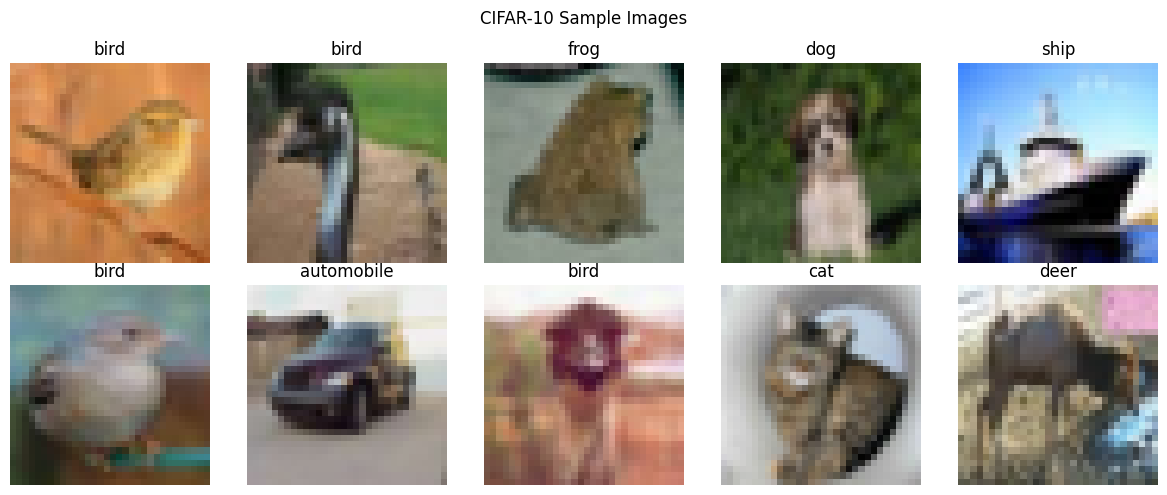

In [8]:
import matplotlib.pyplot as plt

classes = (
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(classes[labels[i].item()])
    ax.axis('off')

plt.suptitle("CIFAR-10 Sample Images")
plt.tight_layout()
plt.show()


task 4:

In [9]:
import torchvision.transforms as transforms
import torch

class AddGaussianNoise:
    def __init__(self, std=0.02):
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std
        return torch.clamp(tensor + noise, 0, 1)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    AddGaussianNoise(std=0.02),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

print("Data Augmentation ready!")


Data Augmentation ready!


In [10]:
train_dataset.transform = train_transform
test_dataset.transform = test_transform

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Augmented training dataset ready!")
print("Testing dataset ready!")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))


Augmented training dataset ready!
Testing dataset ready!
Training samples: 50000
Testing samples: 10000


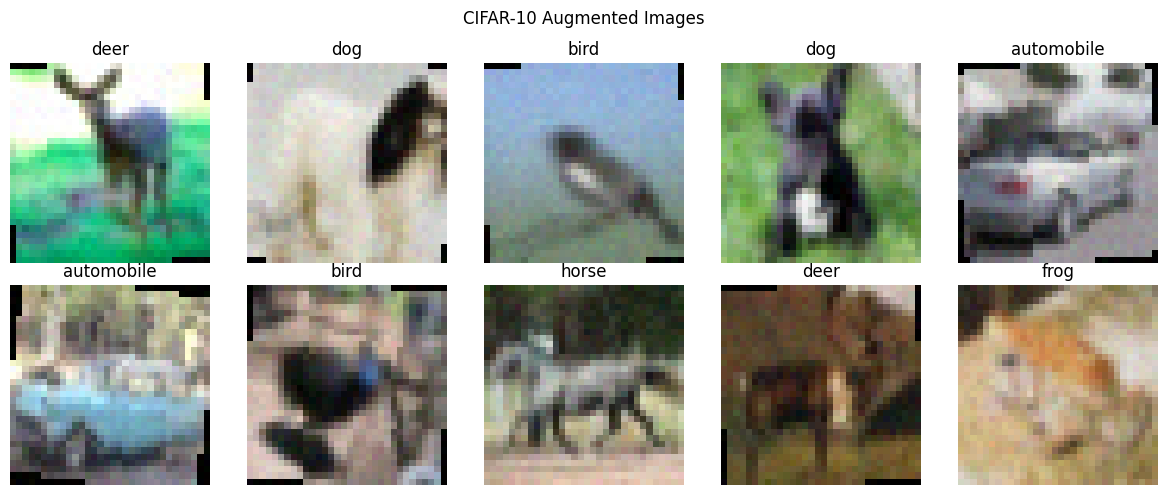

In [11]:
import matplotlib.pyplot as plt

aug_images, aug_labels = next(iter(train_loader))

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = aug_images[i] * std + mean
    image = image.clamp(0, 1)
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[aug_labels[i].item()])
    ax.axis("off")

plt.suptitle("CIFAR-10 Augmented Images")
plt.tight_layout()
plt.show()


task 5:

In [12]:
import matplotlib.pyplot as plt
import time

epochs = 5

train_losses = []
test_losses = []
test_accuracies = []

start_time = time.time()

for epoch in range(epochs):

    train_loss, train_acc = train(
        model, train_loader, criterion, optimizer
    )

    test_loss, test_acc = test(
        model, test_loader, criterion
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    test_accuracies.append(test_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_acc:.2f}%"
    )

print("Training completed!")
print("Training time:", round(time.time() - start_time, 2), "seconds")


Epoch [1/5] Train Loss: 1.4748 | Train Accuracy: 47.12% | Test Loss: 1.1119 | Test Accuracy: 60.20%
Epoch [2/5] Train Loss: 1.1555 | Train Accuracy: 59.03% | Test Loss: 1.0266 | Test Accuracy: 64.36%
Epoch [3/5] Train Loss: 1.0342 | Train Accuracy: 63.70% | Test Loss: 0.9190 | Test Accuracy: 67.89%
Epoch [4/5] Train Loss: 0.9664 | Train Accuracy: 66.00% | Test Loss: 0.8803 | Test Accuracy: 69.49%
Epoch [5/5] Train Loss: 0.9135 | Train Accuracy: 68.03% | Test Loss: 0.8675 | Test Accuracy: 70.26%
Training completed!
Training time: 733.82 seconds


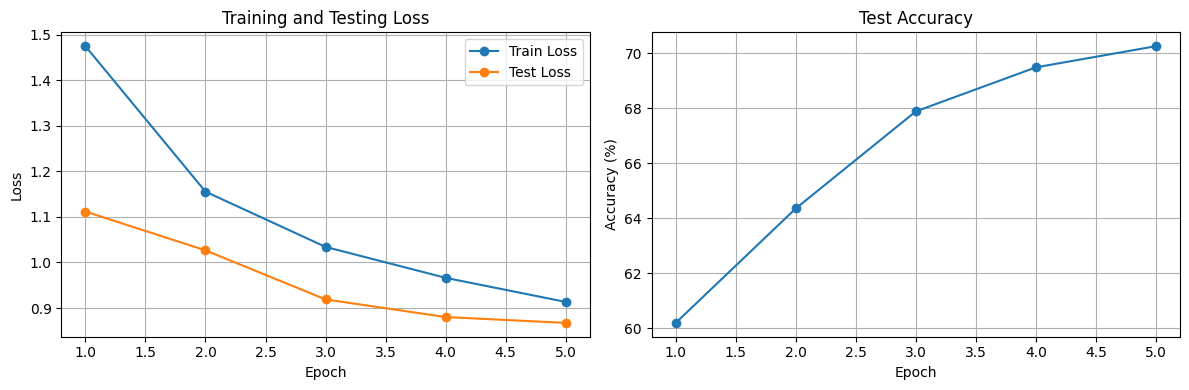

In [13]:
epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_losses, marker='o', label='Train Loss')
plt.plot(epoch_numbers, test_losses, marker='o', label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Testing Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, test_accuracies, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Test Accuracy')
plt.grid(True)

plt.tight_layout()
plt.show()


In [14]:
print("Experiment 1 Results")
print("----------------------")
print(f"Final Train Loss: {train_losses[-1]:.4f}")
print(f"Final Test Loss: {test_losses[-1]:.4f}")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")
print("Learning Rate: 0.001")
print("Batch Size: 64")
print("Epochs: 5")
print("Optimizer: Adam")


Experiment 1 Results
----------------------
Final Train Loss: 0.9135
Final Test Loss: 0.8675
Final Test Accuracy: 70.26%
Learning Rate: 0.001
Batch Size: 64
Epochs: 5
Optimizer: Adam


In [19]:
model2 = CNN().to(device)

train_loader2 = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader2 = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

optimizer2 = optim.Adam(model2.parameters(), lr=0.0005)

train_losses2 = []
test_losses2 = []
test_accuracies2 = []

epochs2 = 5

start_time = time.time()

for epoch in range(epochs2):

    train_loss2, train_acc2 = train(
        model2, train_loader2, criterion, optimizer2
    )

    test_loss2, test_acc2 = test(
        model2, test_loader2, criterion
    )

    train_losses2.append(train_loss2)
    test_losses2.append(test_loss2)
    test_accuracies2.append(test_acc2)

    print(
        f"Epoch [{epoch+1}/{epochs2}] "
        f"Train Loss: {train_loss2:.4f} | "
        f"Train Accuracy: {train_acc2:.2f}% | "
        f"Test Loss: {test_loss2:.4f} | "
        f"Test Accuracy: {test_acc2:.2f}%"
    )

print("Experiment 2 completed!")
print("Training time:", round(time.time() - start_time, 2), "seconds")


Epoch [1/5] Train Loss: 1.6198 | Train Accuracy: 41.88% | Test Loss: 1.3175 | Test Accuracy: 52.78%
Epoch [2/5] Train Loss: 1.3506 | Train Accuracy: 52.16% | Test Loss: 1.1504 | Test Accuracy: 59.31%
Epoch [3/5] Train Loss: 1.2314 | Train Accuracy: 56.63% | Test Loss: 1.0596 | Test Accuracy: 62.70%
Epoch [4/5] Train Loss: 1.1477 | Train Accuracy: 59.47% | Test Loss: 1.0227 | Test Accuracy: 63.78%
Epoch [5/5] Train Loss: 1.0932 | Train Accuracy: 61.47% | Test Loss: 0.9586 | Test Accuracy: 66.08%
Experiment 2 completed!
Training time: 797.05 seconds


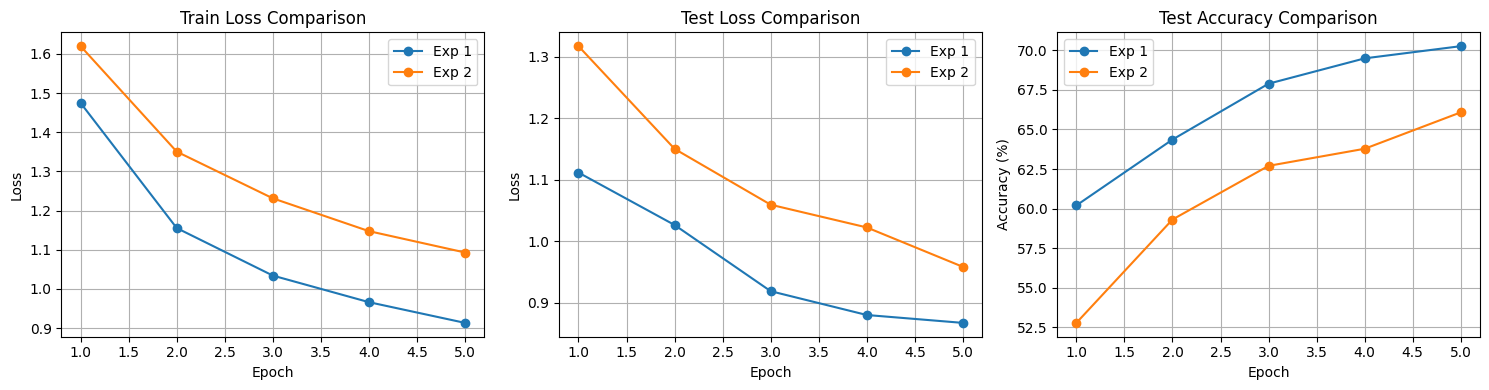

In [20]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(range(1, 6), train_losses, marker='o', label='Exp 1')
plt.plot(range(1, 6), train_losses2, marker='o', label='Exp 2')
plt.title("Train Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(range(1, 6), test_losses, marker='o', label='Exp 1')
plt.plot(range(1, 6), test_losses2, marker='o', label='Exp 2')
plt.title("Test Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(range(1, 6), test_accuracies, marker='o', label='Exp 1')
plt.plot(range(1, 6), test_accuracies2, marker='o', label='Exp 2')
plt.title("Test Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [21]:
import pandas as pd

results = pd.DataFrame({
    "Experiment": ["Experiment 1", "Experiment 2"],
    "Learning Rate": [0.001, 0.0005],
    "Batch Size": [64, 128],
    "Epochs": [5, 5],
    "Train Loss": [train_losses[-1], train_losses2[-1]],
    "Test Loss": [test_losses[-1], test_losses2[-1]],
    "Test Accuracy (%)": [
        test_accuracies[-1],
        test_accuracies2[-1]
    ]
})

display(results)

best = results.loc[results["Test Accuracy (%)"].idxmax()]
print("Best Experiment:", best["Experiment"])
print("Best Test Accuracy:", round(best["Test Accuracy (%)"], 2), "%")


,Experiment,Learning Rate,Batch Size,Epochs,Train Loss,Test Loss,Test Accuracy (%)
0,Experiment 1,0.0010,64,5,0.913490,0.867456,70.26
1,Experiment 2,0.0005,128,5,1.093152,0.958580,66.08


Best Experiment: Experiment 1
Best Test Accuracy: 70.26 %
